In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import os
import random
import re
from collections import Counter
from datetime import timedelta

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, KFold, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.utils import to_categorical
from tcn import TCN
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Activation,
    Add,
    BatchNormalization,
    Concatenate,
    Conv1D,
    Dense,
    Dropout,
    Embedding,
    Flatten,
    GlobalAveragePooling1D,
    Input,
    MaxPooling1D,
)
from tensorflow.keras.models import Model, Sequential

# ===== Machine learning / optimization =====
import joblib
import lightgbm as lgb
import optuna
import shap

In [3]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

## Read data and assing age groups

In [ ]:
from joblib import load
X_feat_test, Y_test = load("Data/ML_Test.joblib")
X_DL_test, Y_test = load("Data/DL_Test.joblib")

In [5]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)



# flattens the arrays of single subjects into one array of shape (X,25,2)
X_test_fold = flatten(X_DL_test)
# flattens the arrays of single subjects into one array of shape (X,1)
Y_test_fold = flatten(Y_test)


Y_test_rs = to_categorical(Y_test_fold)


# converts train, val, and test data into tensors
X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)



##### Data for static #####


# data are flattened to match the required shape
X_test_feat_all = flatten(X_feat_test)

Y_test_all = Y_test_fold.reshape(-1)

In [6]:
print(X_test_t.shape)
print(Y_test_t.shape)
print(X_test_fold.shape)
print(Y_test_fold.shape)
print(X_test_feat_all.shape)
print(Y_test_all.shape)

(3552429, 25, 1)
(3552429, 4)
(3552429, 25, 1)
(3552429, 1)
(3552429, 83)
(3552429,)


In [7]:
np.bincount(Y_test_all)

array([1199210,  340979,  626318, 1385922])

## Random Forest

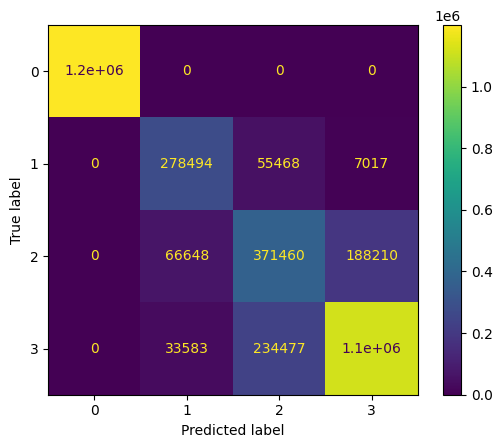


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7353    0.8167    0.7739    340979
           2     0.5616    0.5931    0.5769    626318
           3     0.8513    0.8066    0.8283   1385922

    accuracy                         0.8352   3552429
   macro avg     0.7871    0.8041    0.7948   3552429
weighted avg     0.8393    0.8352    0.8367   3552429



In [ ]:
#shap based feature analysis of RF model 

## now select the best performing fold
model_rf=joblib.load('Saved_Models/model_rf.pkl')

y_pred_prob_rf = model_rf.predict_proba(X_test_feat_all)
y_pred_labels_rf = model_rf.predict(X_test_feat_all)

ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_rf)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_rf, digits=4))

In [13]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= y_pred_prob_rf
y_pred_labels = y_pred_labels_rf

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("RF_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[1.0, 0.8592621873167258, 0.5883860625181643, 0.912343736283552]]
Mac PR AUC: ([np.float64(0.8399979965296105)])


## LightGBM

In [9]:
a = [
 'GlucoseCGM', 'diff_5', 'diff_10', 'diff_20', 'diff_40', 'GlucoseCGM_mean_30min', 'GlucoseCGM_std_30min', 'GlucoseCGM_min_30min', 'GlucoseCGM_max_30min', 'n_30min', 'time_below70_30min', 'time_above200_30min', 'diff_30min', 'slope_30min', 'GlucoseCGM_mean_1hr',
 'GlucoseCGM_std_1hr', 'GlucoseCGM_min_1hr', 'GlucoseCGM_max_1hr', 'n_1hr', 'time_below70_1hr', 'time_above200_1hr', 'diff_1hr', 'slope_1hr', 'GlucoseCGM_mean_2hr', 'GlucoseCGM_std_2hr', 'GlucoseCGM_min_2hr', 'GlucoseCGM_max_2hr', 'n_2hr', 'time_below70_2hr', 'time_above200_2hr', 'diff_2hr', 'slope_2hr', 'GlucoseCGM_mean_4hr', 'GlucoseCGM_std_4hr',  'GlucoseCGM_min_4hr', 'GlucoseCGM_max_4hr', 'n_4hr', 'time_below70_4hr',
 'time_above200_4hr', 'diff_4hr', 'slope_4hr', 'GlucoseCGM_mean_8hr', 'GlucoseCGM_std_8hr', 'GlucoseCGM_min_8hr', 'GlucoseCGM_max_8hr', 'n_8hr', 'time_below70_8hr',
 'time_above200_8hr', 'diff_8hr', 'slope_8hr', 'GlucoseCGM_mean_24hr', 'GlucoseCGM_std_24hr', 'GlucoseCGM_min_24hr', 'GlucoseCGM_max_24hr', 'n_24hr', 'time_below70_24hr',  'time_above200_24hr',  'diff_24hr', 'slope_24hr', 'hypo_points_30m', 'avg_event_duration_min_30m', 'min_since_last_event_30m', 'hypo_points_1h', 'avg_event_duration_min_1h', 'min_since_last_event_1h', 'hypo_points_2h', 'avg_event_duration_min_2h', 'min_since_last_event_2h', 'hypo_points_4h', 'avg_event_duration_min_4h', 'min_since_last_event_4h',  'hypo_points_24h', 'avg_event_duration_min_24h', 'min_since_last_event_24h', 'hour', 'minute', 'dayofweek', 'valid_30min', 'valid_1hr', 'valid_2hr', 'valid_4hr',  'valid_8hr', 'valid_24hr',]

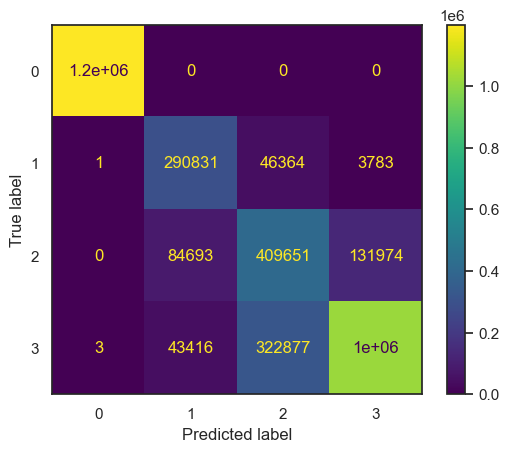


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6942    0.8529    0.7654    340979
           2     0.5259    0.6541    0.5830    626318
           3     0.8825    0.7357    0.8024   1385922

    accuracy                         0.8218   3552429
   macro avg     0.7757    0.8107    0.7877   3552429
weighted avg     0.8412    0.8218    0.8269   3552429



In [ ]:
#shap based feature analysis of LighGBM model 

model_lbgm= joblib.load('Saved_Models/model_lgm.pkl')
X_test_feat_all_df = pd.DataFrame(X_test_feat_all, columns=a)

y_pred_labels_lbgm = model_lbgm.predict(X_test_feat_all_df)
y_pred_prob_lbgm = model_lbgm.predict_proba(X_test_feat_all_df)
ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_lbgm)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_lbgm, digits=4))

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= y_pred_prob_lbgm
y_pred_labels = y_pred_labels_lbgm
y_pred_labels_rf

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("LGBM_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[1.0, 0.8580817848020983, 0.5735696446710092, 0.9136774853233434]]
Mac PR AUC: ([np.float64(0.8363322286991126)])


### Explain

/var/folders/t1/sgksm9r9385br4pts_lckj1w0000gn/T/ipykernel_24962/3380560053.py:20: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_lbgm, X_test_subset, plot_type="bar")


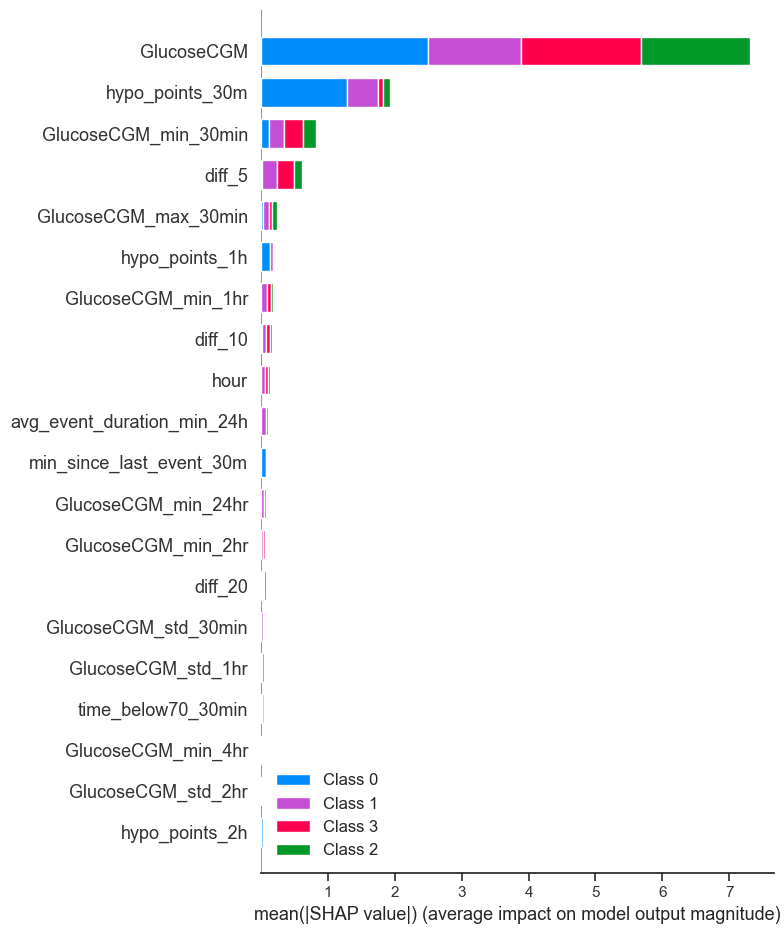

In [11]:
import shap
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


# Assuming X_train is a numpy array
X_test_df = pd.DataFrame(X_test_feat_all, columns=a)

# Sample 10% of the data from X_train
X_test_subset = X_test_df.sample(frac=0.10, random_state=42)

explainer_lbgm = shap.TreeExplainer(model_lbgm)
shap_values_lbgm = explainer_lbgm.shap_values(X_test_subset, check_additivity=False)


shap.summary_plot(shap_values_lbgm, X_test_subset, plot_type="bar")

In [14]:
import joblib

# save explainer
joblib.dump(explainer_lbgm, "explainer_lbgm.pkl")

# save shap values
joblib.dump(shap_values_lbgm, "shap_values_lbgm.pkl")

['shap_values_lbgm.pkl']

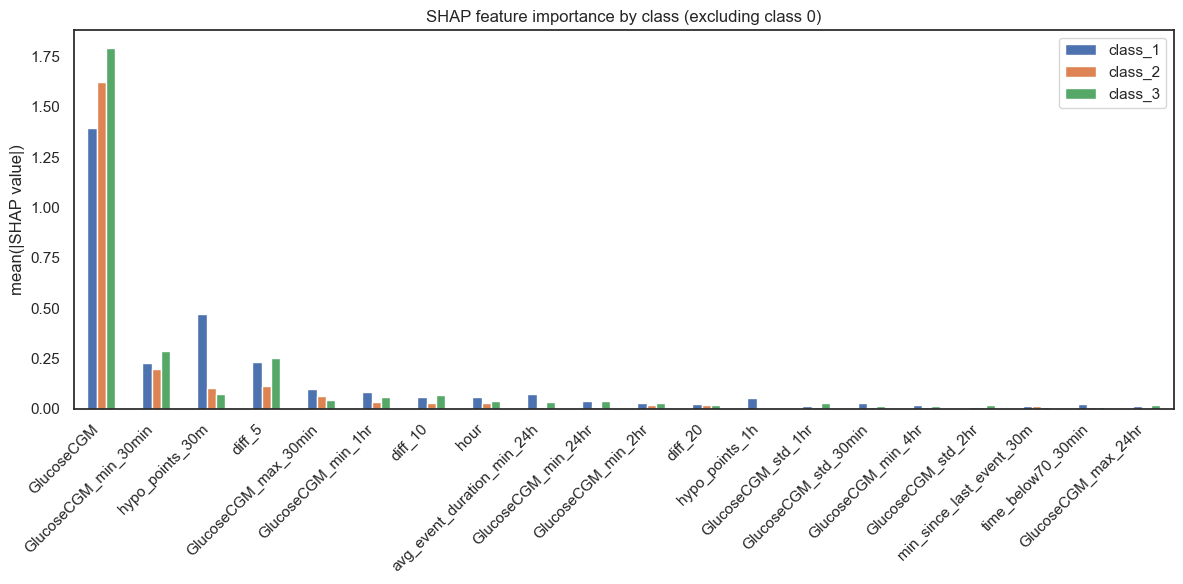

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


sv = shap_values_lbgm        # shape (n, f, c) = (500, 83, 4)
X = X_test_df                     # shape (500, 83) with column names

ignore_class = 0           # set None if you want all classes
top_k = 20                    # how many features to show

# choose classes to plot
classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

# mean absolute shap per feature per class -> (f, len(classes))
imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

# dataframe for plotting
df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

# pick top features by average importance across plotted classes
top_features = df.mean(axis=1).sort_values(ascending=False).head(top_k).index
df_top = df.loc[top_features]

# plot grouped bars (different colors automatically)
ax = df_top.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("mean(|SHAP value|)")
ax.set_title("SHAP feature importance by class" + (f" (excluding class {ignore_class})" if ignore_class is not None else ""))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


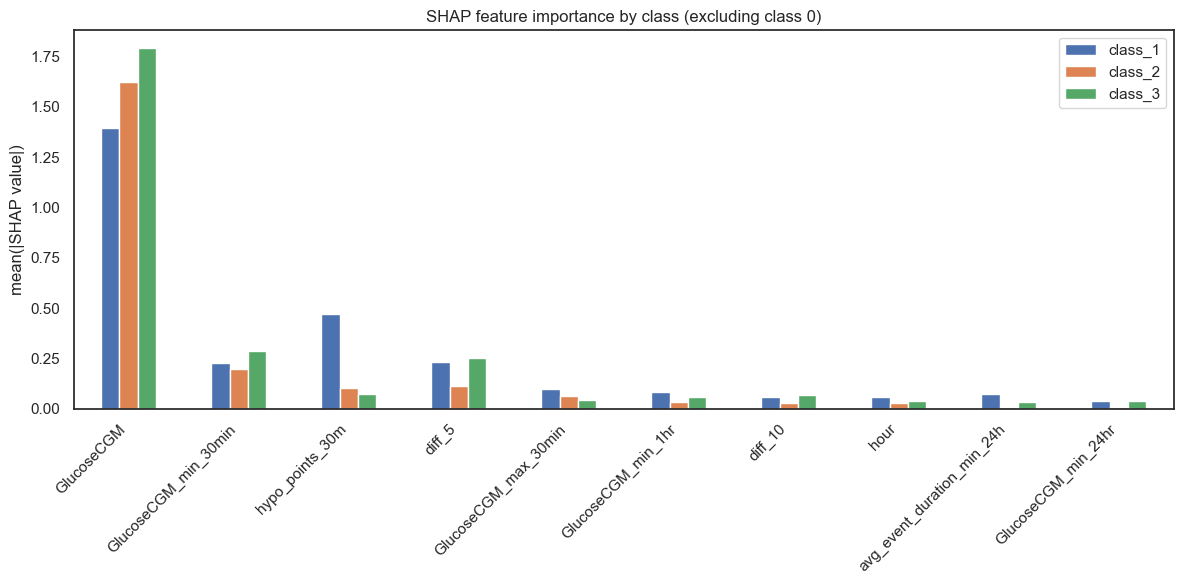

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


sv = shap_values_lbgm        # shape (n, f, c) = (500, 83, 4)
X = X_test_df                     # shape (500, 83) with column names

ignore_class = 0           # set None if you want all classes
top_k = 10         # how many features to show

# choose classes to plot
classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

# mean absolute shap per feature per class -> (f, len(classes))
imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

# dataframe for plotting
df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

# pick top features by average importance across plotted classes
top_features = df.mean(axis=1).sort_values(ascending=False).head(top_k).index
df_top = df.loc[top_features]

# plot grouped bars (different colors automatically)
ax = df_top.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("mean(|SHAP value|)")
ax.set_title("SHAP feature importance by class" + (f" (excluding class {ignore_class})" if ignore_class is not None else ""))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## TCN

In [20]:
from joblib import load
X_train, Y_train = load("Data/DataTrain_Multiclass_DL.joblib")

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]


print(len(train_idx))


# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)


print(X_train_fold.shape)

# initiliazes buffer size and batch size 
"""BUFFER_SIZE = len(X_train_fold) 
BATCH_SIZE = 64"""

BATCH_SIZE =  256 #1024 #512 #2048 #256
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)


# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)

1906
(12891361, 25, 1)


111014/111014 ━━━━━━━━━━━━━━━━━━━━ 472s 4ms/step


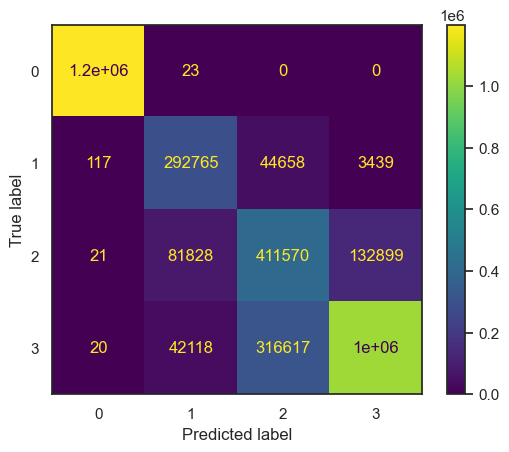

              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999   1199210
           1     0.7025    0.8586    0.7728    340979
           2     0.5325    0.6571    0.5883    626318
           3     0.8828    0.7411    0.8058   1385922

    accuracy                         0.8250   3552429
   macro avg     0.7794    0.8142    0.7917   3552429
weighted avg     0.8433    0.8250    0.8298   3552429



In [ ]:
#IG based feature analysis of FCN model 
from keras.models import load_model

model_tcn = load_model("Saved_Models/TCN_model_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_test_t)

y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
    

final_preds_tcn = y_pred_tcn

y_true_labels_tcn = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn, final_preds_tcn)
plt.show()

report_tcn = classification_report(y_true_labels_tcn, final_preds_tcn, digits=4)
print(report_tcn)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= predictions_tcn
y_pred_labels = y_pred_tcn

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("TCN_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[0.9999995209344728, 0.8729106260419567, 0.581759426644209, 0.9154006595897954]]
Mac PR AUC: ([np.float64(0.8425175583026083)])


## TCN MHAL

111014/111014 ━━━━━━━━━━━━━━━━━━━━ 580s 5ms/step


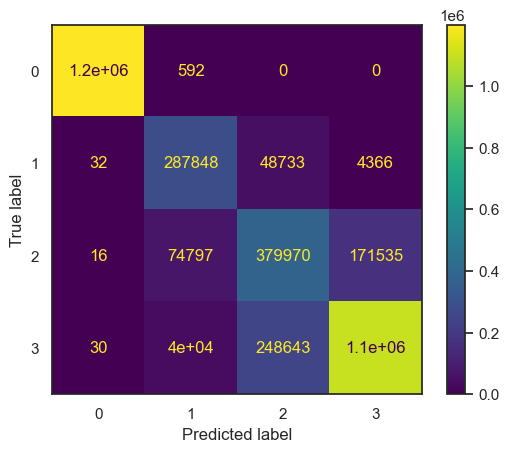

              precision    recall  f1-score   support

           0     0.9999    0.9995    0.9997   1199210
           1     0.7140    0.8442    0.7736    340979
           2     0.5610    0.6067    0.5829    626318
           3     0.8618    0.7918    0.8253   1385922

    accuracy                         0.8343   3552429
   macro avg     0.7842    0.8105    0.7954   3552429
weighted avg     0.8412    0.8343    0.8365   3552429



In [ ]:
#IG based feature analysis of FCN model 
from keras.models import load_model



model_tcn_mhal = load_model("Saved_Models/TCN_model_MHAL_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn_mhal = model_tcn_mhal.predict(X_test_t)

y_pred_tcn_mhal = np.argmax(predictions_tcn_mhal, axis=1) 
    
final_preds_tcn_mhal = y_pred_tcn_mhal


y_true_labels_tcn_mhal = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal, final_preds_tcn_mhal)
plt.show()

report_fcn_tcn_mhal = classification_report(y_true_labels_tcn_mhal, final_preds_tcn_mhal, digits=4)
print(report_fcn_tcn_mhal)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= predictions_tcn_mhal
y_pred_labels = y_pred_tcn_mhal

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("TCN_MHAL_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[0.9999997007521337, 0.8703691311989293, 0.5977801938101914, 0.9149606691740315]]
Mac PR AUC: ([np.float64(0.8457774237338216)])


## Ensemble Soft Voting

In [ ]:
RF_true = load("Outputs/y_true_RF.joblib")
RF_proba = load("Outputs/y_pred_prob_RF.joblib")

LightGBM_true = load("Outputs/y_true_LBG1.joblib")
LightGBM_proba = load("Outputs/y_pred_prob_LBG1.joblib")

TCN_true = load("Outputs/y_true_TCN.joblib")
TCN_proba = load("Outputs/y_pred_prob_TCN.joblib")

TCN_MHAL_true = load("Outputs/y_true_TCN_MH.joblib")
TCN_MHAL_proba = load("Outputs/y_pred_prob_TCN_MH.joblib")

In [88]:
a = flatten(flatten(TCN_true))
b = flatten(flatten(TCN_MHAL_true))
c = flatten(LightGBM_true)
d = flatten(RF_true)

In [90]:
import numpy as np

arrays = {
    "a": a,
    "b": b,
    "c": c,
    "d": d,
}

# Compare all pairs
names = list(arrays.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        n1, n2 = names[i], names[j]

        equal = np.array_equal(arrays[n1], arrays[n2])

        print(f"{n1} vs {n2}: {equal}")

a vs b: True
a vs c: True
a vs d: True
b vs c: True
b vs d: True
c vs d: True


In [86]:
same = (
    len(a) == len(b)
    and all(np.array_equal(x, y) for x, y in zip(a, b))
)

print(same)

True


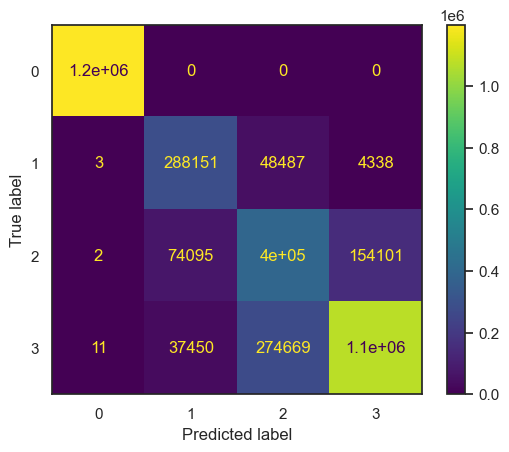

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7209    0.8451    0.7781    340979
           2     0.5520    0.6357    0.5909    626318
           3     0.8714    0.7748    0.8203   1385922

    accuracy                         0.8330   3552429
   macro avg     0.7861    0.8139    0.7973   3552429
weighted avg     0.8441    0.8330    0.8364   3552429



In [95]:
all_proba = np.mean(
    np.stack([y_pred_prob_rf, y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal], axis=0),
    axis=0
)  
y_pred_all = np.argmax(all_proba, axis=1) 

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_all)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred_all, digits=4)
print(report_fcn)

In [96]:
from sklearn.metrics import f1_score

f1_rf  =  f1_score(Y_test_all, y_pred_labels_rf, average='macro') 
f1_lgb = f1_score(Y_test_all, y_pred_labels_lbgm,  average="macro") 
f1_tcn = f1_score(Y_test_all, y_pred_tcn_mhal, average="macro")
f1_tcn_mhal = f1_score(Y_test_all, y_pred_tcn_mhal, average="macro")

print(f1_rf, f1_lgb,  f1_tcn, f1_tcn_mhal)

weights = [f1_rf, f1_lgb,f1_tcn, f1_tcn_mhal]

weights = np.array(weights)
weights = weights / weights.mean()
print(weights)

0.7947968181884354 0.7877283593114712 0.7954002625617791 0.7954002625617791
[1.00184714 0.99293729 1.00260778 1.00260778]


In [97]:
f1s = np.array([f1_rf, f1_lgb, f1_tcn, f1_tcn_mhal], dtype=float)
eps = 1e-8
weights_nrm = (f1s + eps) / (f1s + eps).sum()
print(weights_nrm)

[0.25046178 0.24823432 0.25065195 0.25065195]


In [99]:
RF_proba = y_pred_prob_rf
LightGBM_proba = y_pred_prob_lbgm
TCN_proba = predictions_tcn
TCN_MHAL_proba = predictions_tcn_mhal

P_ens = (
    weights[0] *RF_proba +
    weights[1] * LightGBM_proba +
    weights[2] * TCN_proba+
    weights[3] * TCN_MHAL_proba
)/4

y_pred_ens = np.argmax(P_ens, axis=1)
y_pred_ens

array([3, 3, 3, ..., 0, 0, 0], shape=(3552429,))

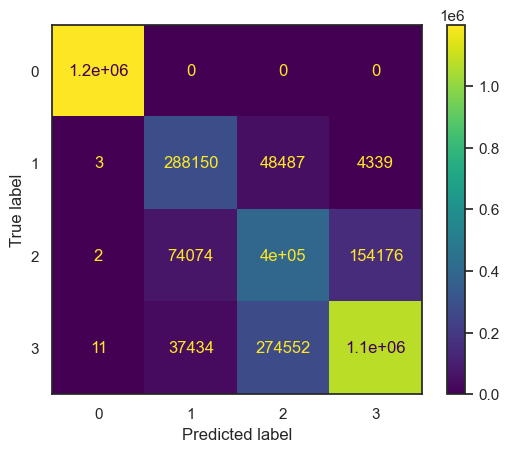

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7210    0.8451    0.7781    340979
           2     0.5520    0.6356    0.5909    626318
           3     0.8714    0.7749    0.8203   1385922

    accuracy                         0.8331   3552429
   macro avg     0.7861    0.8139    0.7973   3552429
weighted avg     0.8441    0.8331    0.8365   3552429



In [100]:
y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred_ens)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred_ens, digits=4)
print(report_fcn)

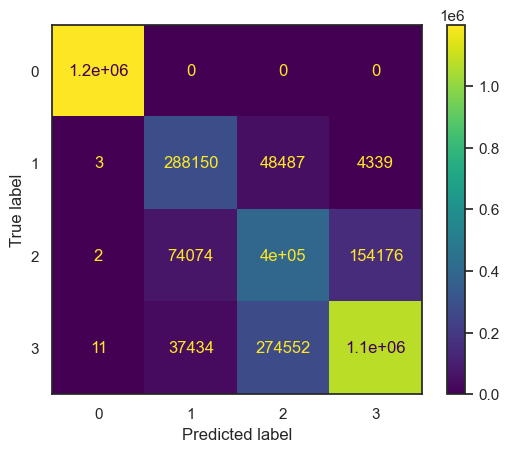

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7210    0.8451    0.7781    340979
           2     0.5520    0.6356    0.5909    626318
           3     0.8714    0.7749    0.8203   1385922

    accuracy                         0.8331   3552429
   macro avg     0.7861    0.8139    0.7973   3552429
weighted avg     0.8441    0.8331    0.8365   3552429



In [101]:
P_ens = (
    weights[0] *RF_proba +
    weights[1] * LightGBM_proba +
    weights[2] * TCN_proba+
    weights[3] * TCN_MHAL_proba
)

y_pred_ens = np.argmax(P_ens, axis=1)


y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred_ens)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred_ens, digits=4)
print(report_fcn)

In [102]:
for avg in ["macro", "weighted"]:
    f1_rf  =  f1_score(Y_test_all, y_pred_labels_rf, average=avg) 
    f1_lgb = f1_score(Y_test_all, y_pred_labels_lbgm,  average=avg) 
    f1_tcn = f1_score(Y_test_all, y_pred_tcn_mhal, average=avg)
    f1_tcn_mhal = f1_score(Y_test_all, y_pred_tcn_mhal, average=avg)

    print(avg, f1_rf, f1_lgb, f1_tcn, f1_tcn_mhal )

macro 0.7947968181884354 0.7877283593114712 0.7954002625617791 0.7954002625617791
weighted 0.8367413513524468 0.826898344198165 0.8364961641270761 0.8364961641270761


In [103]:
import numpy as np
from sklearn.metrics import f1_score

f1_rf  = f1_score(Y_test_all, y_pred_labels_rf,  average=None, labels=np.arange(4))
f1_lgb = f1_score(Y_test_all, y_pred_labels_lbgm,  average=None, labels=np.arange(4))
f1_tcn = f1_score(Y_test_all, y_pred_tcn_mhal, average=None, labels=np.arange(4))
f1_tcn_mhal = f1_score(Y_test_all, y_pred_tcn_mhal, average=None, labels=np.arange(4))

In [104]:
F = np.vstack([f1_rf, f1_lgb, f1_tcn, f1_tcn_mhal ])

In [105]:
eps = 1e-8
W = (F + eps) / (F + eps).sum(axis=0, keepdims=True)

In [106]:
S = (
    RF_proba   * W[0] +
    LightGBM_proba * W[1] +

   TCN_proba * W[2]+
   TCN_MHAL_proba * W[3]

)


In [107]:
S_sum = S.sum(axis=1, keepdims=True)
P_ens = S / np.clip(S_sum, 1e-12, None)

y_pred = P_ens.argmax(axis=1)

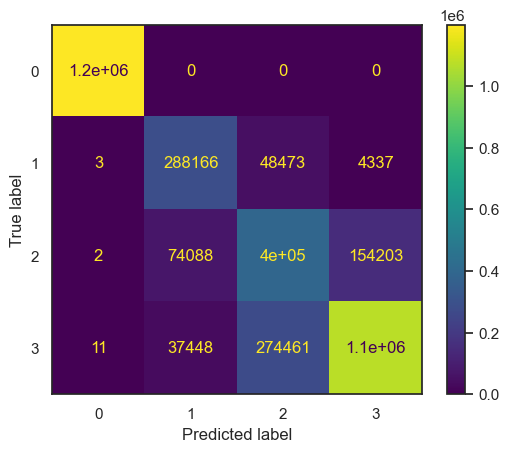

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7210    0.8451    0.7781    340979
           2     0.5521    0.6355    0.5909    626318
           3     0.8714    0.7749    0.8203   1385922

    accuracy                         0.8331   3552429
   macro avg     0.7861    0.8139    0.7973   3552429
weighted avg     0.8441    0.8331    0.8365   3552429



In [108]:
y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

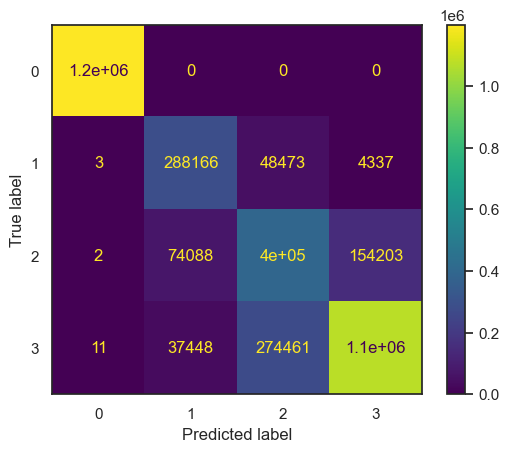

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7210    0.8451    0.7781    340979
           2     0.5521    0.6355    0.5909    626318
           3     0.8714    0.7749    0.8203   1385922

    accuracy                         0.8331   3552429
   macro avg     0.7861    0.8139    0.7973   3552429
weighted avg     0.8441    0.8331    0.8365   3552429



In [109]:
import numpy as np
from sklearn.metrics import recall_score

rc_rf  = recall_score(Y_test_all, y_pred_labels_rf, average=None, labels=np.arange(4))
rc_lgb = recall_score(Y_test_all, y_pred_labels_lbgm, average=None, labels=np.arange(4))
rc_tcn = recall_score(Y_test_all, y_pred_tcn_mhal,average=None, labels=np.arange(4))
rc_tcn_mhal = recall_score(Y_test_all, y_pred_tcn_mhal, average=None, labels=np.arange(4))

RC = np.vstack([rc_rf, rc_lgb,  rc_tcn, rc_tcn_mhal])
eps = 1e-8
WR = (RC + eps) / (RC + eps).sum(axis=0, keepdims=True)

SR = (
    RF_proba   * W[0] +
    LightGBM_proba * W[1] +

   TCN_proba * W[2]+
   TCN_MHAL_proba * W[3]
)

S_sum = SR.sum(axis=1, keepdims=True)
P_ens = SR / np.clip(S_sum, 1e-12, None)

y_pred = P_ens.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [110]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= P_ens
y_pred_labels = y_pred

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("model_soft_avg.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[0.9999999999993047, 0.873170408017135, 0.5994613314793168, 0.9170589550703007]]
Mac PR AUC: ([np.float64(0.8474226736415142)])


## Ensemble Stacking 

In [ ]:
RF_true = load("Outputs/y_true_RF.joblib")
RF_proba = flatten(load("Outputs/y_pred_prob_RF.joblib"))

LightGBM_true = load("Outputs/y_true_LBG1.joblib")
LightGBM_proba = flatten(load("Outputs/y_pred_prob_LBG1.joblib"))

TCN_true = load("Outputs/y_true_TCN.joblib")
TCN_proba = flatten(load("Outputs/y_pred_prob_TCN.joblib"))

TCN_MHAL_true = load("Outputs/y_true_TCN_MH.joblib")
TCN_MHAL_proba = flatten(load("Outputs/y_pred_prob_TCN_MH.joblib"))

In [121]:
flatten(RF_true)

array([3, 3, 3, ..., 0, 0, 0], shape=(12891361,))

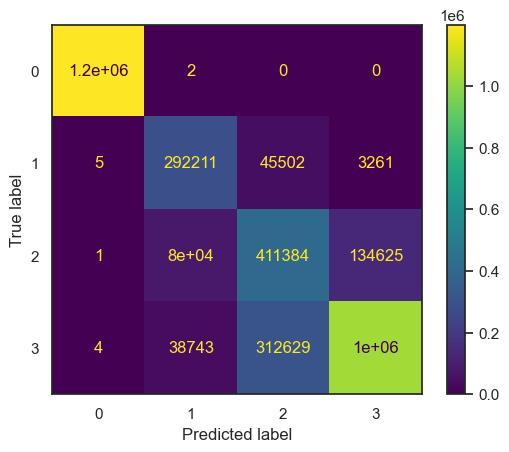

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7105    0.8570    0.7769    340979
           2     0.5346    0.6568    0.5894    626318
           3     0.8824    0.7465    0.8088   1385922

    accuracy                         0.8269   3552429
   macro avg     0.7819    0.8151    0.7938   3552429
weighted avg     0.8443    0.8269    0.8316   3552429



In [139]:
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

from sklearn.linear_model import LogisticRegression
X_meta_val = np.hstack([RF_proba, TCN_proba])  # (n_val, 3*n_classes) 
meta = LogisticRegression(solver="lbfgs", max_iter=500,  C=1.0,class_weight="balanced", random_state =42)
meta.fit(X_meta_val, flatten(RF_true))

# 500
X_meta_test = np.hstack([y_pred_prob_rf, predictions_tcn])  
P_ens_test = meta.predict_proba(X_meta_test)
y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [150]:
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

from sklearn.linear_model import LogisticRegression
X_meta_val = np.hstack([RF_proba, LightGBM_proba, TCN_proba, TCN_MHAL_proba])  # (n_val, 3*n_classes) 
meta = LogisticRegression(solver="lbfgs", max_iter=500,  C=1.0,class_weight="balanced", random_state =42)
meta.fit(X_meta_val, flatten(RF_true))

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

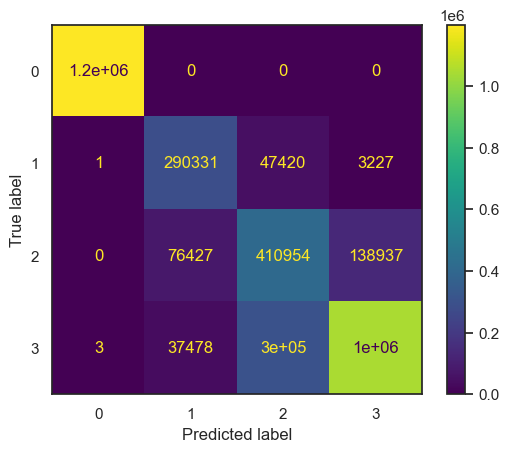

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7182    0.8515    0.7792    340979
           2     0.5403    0.6561    0.5926    626318
           3     0.8804    0.7549    0.8128   1385922

    accuracy                         0.8295   3552429
   macro avg     0.7847    0.8156    0.7962   3552429
weighted avg     0.8452    0.8295    0.8340   3552429



In [166]:
# 500
X_meta_test = np.hstack([y_pred_prob_rf, y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal])  
P_ens_test = meta.predict_proba(X_meta_test)
y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [168]:
P_ens_test

array([[1.94610334e-06, 1.85620531e-03, 2.59608171e-02, 9.72181032e-01],
       [1.93062146e-06, 1.84545591e-03, 2.51578817e-02, 9.72994732e-01],
       [2.48769311e-06, 2.77593201e-03, 4.83544844e-02, 9.48867096e-01],
       ...,
       [9.99985688e-01, 7.04147626e-06, 3.33394423e-06, 3.93657559e-06],
       [9.99986248e-01, 6.72418554e-06, 3.21988854e-06, 3.80827229e-06],
       [9.99973068e-01, 1.33727164e-05, 6.34538692e-06, 7.21436131e-06]],
      shape=(3552429, 4))

In [170]:
Y_test_all

array([3, 3, 3, ..., 1, 1, 0], shape=(40971,))

In [169]:
y_pred

array([3, 3, 3, ..., 0, 0, 0], shape=(3552429,))

In [173]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= P_ens_test
y_pred_labels = y_pred

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("model_ensemble_Dia.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[0.9999999999972186, 0.8748387838555947, 0.6039986671922092, 0.9176998570112916]]
Mac PR AUC: ([np.float64(0.8491343270140785)])


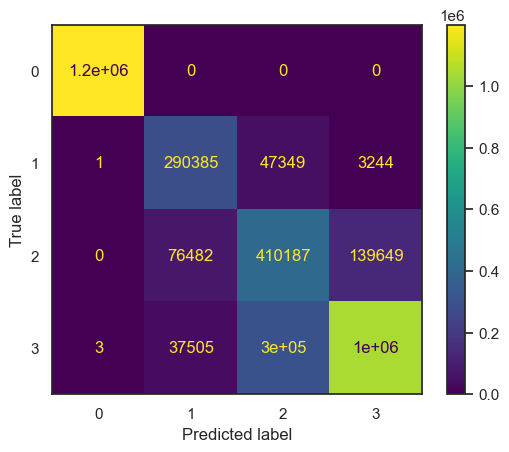

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7181    0.8516    0.7792    340979
           2     0.5410    0.6549    0.5925    626318
           3     0.8800    0.7560    0.8133   1385922

    accuracy                         0.8297   3552429
   macro avg     0.7848    0.8156    0.7962   3552429
weighted avg     0.8452    0.8297    0.8341   3552429



In [137]:
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

from sklearn.linear_model import LogisticRegression

meta = LogisticRegression(solver="lbfgs", max_iter=500,  C=0.01,class_weight="balanced", random_state =42)
meta.fit(X_meta_val, flatten(RF_true))

# 500
P_ens_test = meta.predict_proba(X_meta_test)
y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

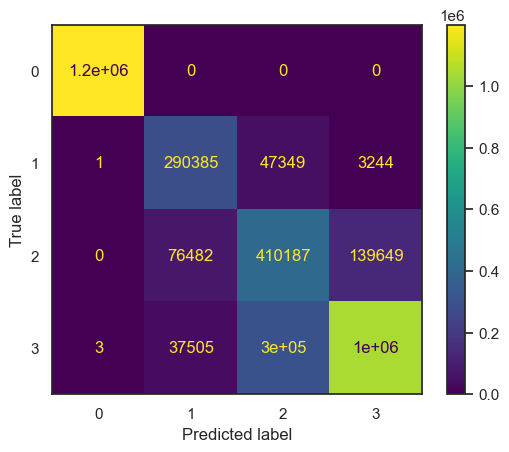

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7181    0.8516    0.7792    340979
           2     0.5410    0.6549    0.5925    626318
           3     0.8800    0.7560    0.8133   1385922

    accuracy                         0.8297   3552429
   macro avg     0.7848    0.8156    0.7962   3552429
weighted avg     0.8452    0.8297    0.8341   3552429



In [138]:
# 500
X_meta_test = np.hstack([y_pred_prob_rf, y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal])  
P_ens_test = meta.predict_proba(X_meta_test)
y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC

meta_models = {
    "logreg_l2": LogisticRegression(C=1.0, penalty="l2", max_iter=2000),
    "logreg_strong_reg": LogisticRegression(C=0.1, penalty="l2", max_iter=2000),
    "ridge": RidgeClassifier()
}

In [ ]:
X_meta_val.shape

(12891361, 12)

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

y_meta_val = flatten(RF_true)

meta = HistGradientBoostingClassifier(
    max_iter=50,
    max_depth=2,
    learning_rate=0.05,
    random_state=42, 
    class_weight="balanced",
    verbose=1,
)

meta.fit(X_meta_val, y_meta_val)

Binning 1.485 GB of training data: 1.109 s
Binning 0.165 GB of validation data: 0.118 s
Fitting gradient boosted rounds:
Fit 200 trees in 45.729 s, (800 total leaves)
Time spent computing histograms: 21.615s
Time spent finding best splits:  0.054s
Time spent applying splits:      3.375s
Time spent predicting:           1.019s


,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.05
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",50
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",2
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide `... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.",'from_dtype

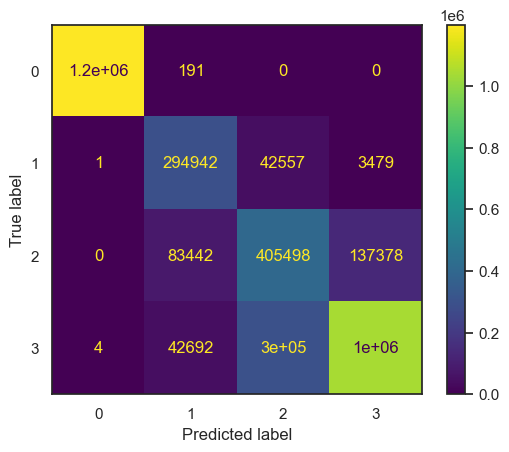

              precision    recall  f1-score   support

           0     1.0000    0.9998    0.9999   1199210
           1     0.7001    0.8650    0.7739    340979
           2     0.5426    0.6474    0.5904    626318
           3     0.8811    0.7533    0.8122   1385922

    accuracy                         0.8286   3552429
   macro avg     0.7810    0.8164    0.7941   3552429
weighted avg     0.8442    0.8286    0.8328   3552429



In [135]:
# 500
y_pred = meta.predict(X_meta_test)
#y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

Binning 1.485 GB of training data: 1.127 s
Binning 0.165 GB of validation data: 0.092 s
Fitting gradient boosted rounds:
Fit 400 trees in 82.387 s, (1600 total leaves)
Time spent computing histograms: 43.970s
Time spent finding best splits:  0.102s
Time spent applying splits:      6.499s
Time spent predicting:           2.005s


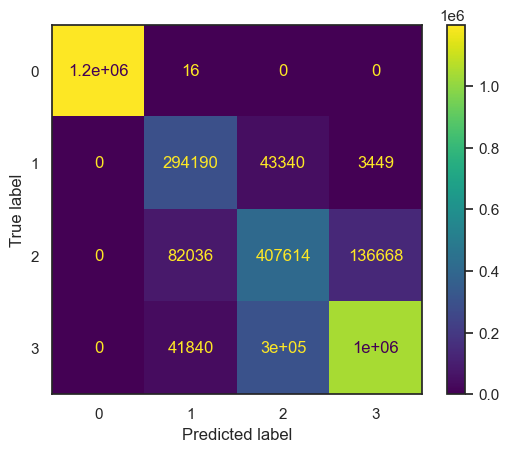

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7037    0.8628    0.7751    340979
           2     0.5417    0.6508    0.5913    626318
           3     0.8815    0.7523    0.8118   1385922

    accuracy                         0.8286   3552429
   macro avg     0.7817    0.8165    0.7945   3552429
weighted avg     0.8445    0.8286    0.8329   3552429



In [136]:
from sklearn.ensemble import HistGradientBoostingClassifier
# base probs on validation
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

y_meta_val = flatten(RF_true)

meta = HistGradientBoostingClassifier(
    max_iter=100,
    max_depth=2,
    learning_rate=0.05,
    random_state=42, 
    class_weight="balanced",
    verbose=1,
)

meta.fit(X_meta_val, y_meta_val)


# 500
y_pred = meta.predict(X_meta_test)
#y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

In [127]:
from sklearn.linear_model import RidgeClassifier
from sklearn.utils.class_weight import compute_sample_weight

y_meta_val = flatten(RF_true)

sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_meta_val
)

meta = RidgeClassifier(
    alpha=1.0,
    class_weight="balanced",
    random_state=42
)

meta.fit(X_meta_val, y_meta_val)

,"alpha alpha: float, default=1.0Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If set to false, nointercept will be used in calculations (e.g. data is expected to bealready centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.The default value is determined by scipy.sparse.linalg.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard scipy.linalg.solve function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in scipy.sparse.linalg.cg. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine scipy.sparse.linalg.lsqr. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its unbiased and more flexible version named SAGA. Both methods use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from sklearn.preprocessing. .. versionadded:: 0.17 Stochastic Average Gradient descent solver. .. versionadded:: 0.19 SAGA solver.- 'lbfgs' uses L-BFGS-B algorithm implemented in `scipy.optimize.minimize`. It can be used only when `positive` is True.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details.",42


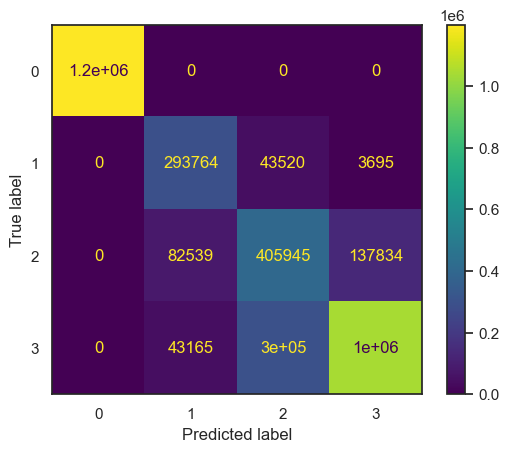

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7003    0.8615    0.7726    340979
           2     0.5428    0.6481    0.5908    626318
           3     0.8806    0.7535    0.8121   1385922

    accuracy                         0.8285   3552429
   macro avg     0.7809    0.8158    0.7939   3552429
weighted avg     0.8441    0.8285    0.8327   3552429



In [128]:
# 500
y_pred = meta.predict(X_meta_test)
#y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

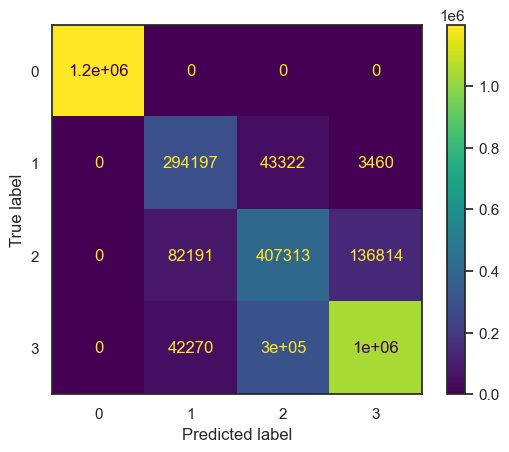

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7027    0.8628    0.7746    340979
           2     0.5420    0.6503    0.5913    626318
           3     0.8814    0.7524    0.8118   1385922

    accuracy                         0.8286   3552429
   macro avg     0.7815    0.8164    0.7944   3552429
weighted avg     0.8445    0.8286    0.8329   3552429



In [132]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report
import numpy as np

X_meta_val = np.hstack([
    RF_proba,
    LightGBM_proba,
    TCN_proba,
    TCN_MHAL_proba
]).astype(np.float32)

y_meta_val = flatten(RF_true)

sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_meta_val
)

meta = XGBClassifier(
    objective="multi:softprob",
    num_class=len(np.unique(y_meta_val)),
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    verbosity=1,
    random_state=42,
    n_jobs=-1
)

meta.fit(
    X_meta_val,
    y_meta_val,
    sample_weight=sample_weight,
    verbose=True
)


X_meta_test = np.hstack([y_pred_prob_rf, y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal]) 
y_pred = meta.predict(X_meta_test)
#y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

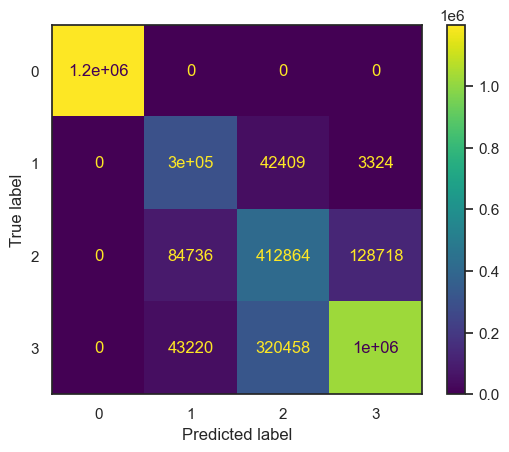

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6976    0.8659    0.7727    340979
           2     0.5322    0.6592    0.5889    626318
           3     0.8856    0.7376    0.8049   1385922

    accuracy                         0.8247   3552429
   macro avg     0.7789    0.8157    0.7916   3552429
weighted avg     0.8439    0.8247    0.8296   3552429



In [141]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report
import numpy as np

X_meta_val = np.hstack([
    RF_proba,
    #LightGBM_proba,
    TCN_proba#,
    #TCN_MHAL_proba
]).astype(np.float32)

y_meta_val = flatten(RF_true)

sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_meta_val
)

meta = XGBClassifier(
    objective="multi:softprob",
    num_class=len(np.unique(y_meta_val)),
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    verbosity=1,
    random_state=42,
    n_jobs=-1
)

meta.fit(
    X_meta_val,
    y_meta_val,
    sample_weight=sample_weight,
    verbose=True
)


X_meta_test = np.hstack([y_pred_prob_rf,predictions_tcn])  
y_pred = meta.predict(X_meta_test)
#y_pred = P_ens_test.argmax(axis=1)

y_true_labels = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels,y_pred)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred, digits=4)
print(report_fcn)

## shap

In [ ]:
def proba_df(name, proba):
    proba = np.asarray(proba)
    return pd.DataFrame(proba, columns=[f"{name}_c{k}" for k in range(proba.shape[1])])

X_meta = pd.concat([
    proba_df("RF", y_pred_prob_rf),
    proba_df("LGBM", y_pred_prob_lbgm), 
    proba_df("TCN", predictions_tcn),
    proba_df("TCN+MHAL", predictions_tcn_mhal)
], axis=1)

In [178]:
import shap

# X_meta: columns = base models' OOF predicted probabilities (or decision scores)
explainer = shap.LinearExplainer(meta, X_meta)

import pandas as pd


shap_values = explainer.shap_values(X_meta)

# global importance per base model
import numpy as np
importance = np.mean(np.abs(shap_values), axis=0)

In [179]:
importance

array([[1.24198155e+00, 4.00082543e-01, 4.32725129e-01, 4.09173879e-01],
       [2.04381167e-01, 6.98319064e-02, 9.09604587e-02, 4.35888022e-02],
       [3.39243547e-01, 4.57819914e-02, 1.37046186e-01, 2.47979353e-01],
       [5.26368582e-01, 4.02929501e-01, 1.19099182e-01, 4.33989920e-03],
       [1.23062426e+00, 3.95341908e-01, 4.24620529e-01, 4.10661821e-01],
       [2.46295116e-01, 1.24123309e-01, 8.02846481e-02, 4.18871592e-02],
       [3.81552744e-01, 3.36397609e-01, 1.16271976e-01, 7.11168415e-02],
       [4.26446079e-01, 2.74972310e-01, 1.92045974e-01, 5.09372414e-01],
       [1.18364167e+00, 3.02529267e-01, 4.55522156e-01, 4.25590249e-01],
       [2.04161812e-01, 4.00060722e-01, 9.64782576e-02, 9.94206521e-02],
       [3.48139244e-01, 1.35232905e-01, 4.82735994e-01, 6.36153741e-04],
       [3.66959854e-01, 1.85844643e-01, 4.42282394e-02, 5.97032736e-01],
       [1.17113026e+00, 2.91493662e-01, 4.55330151e-01, 4.24306447e-01],
       [1.97539235e-01, 2.60995126e-01, 1.91919705e

/var/folders/t1/sgksm9r9385br4pts_lckj1w0000gn/T/ipykernel_18543/1927716012.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_meta, plot_type="bar",  max_display=15)


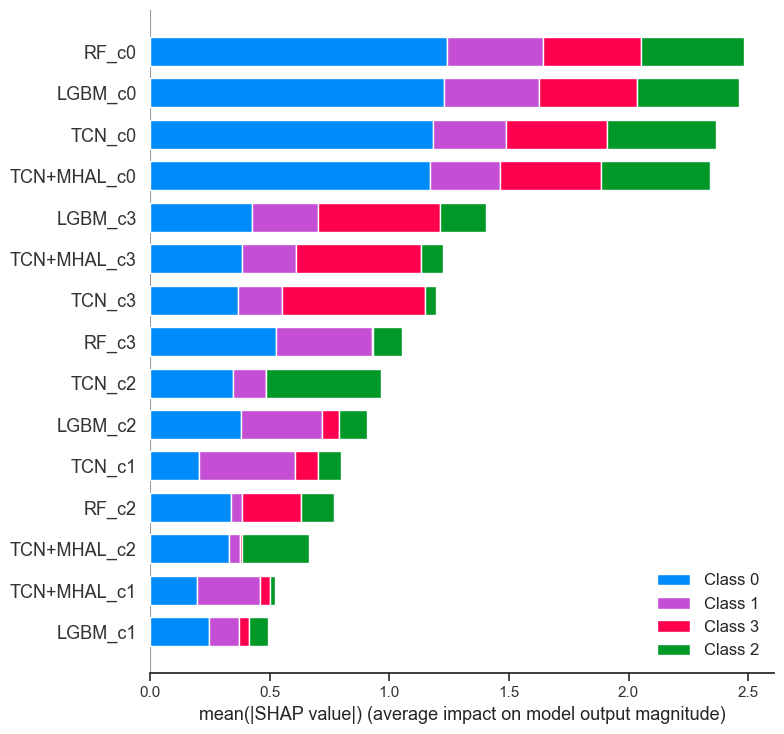

In [182]:
shap.summary_plot(shap_values, X_meta, plot_type="bar",  max_display=15)

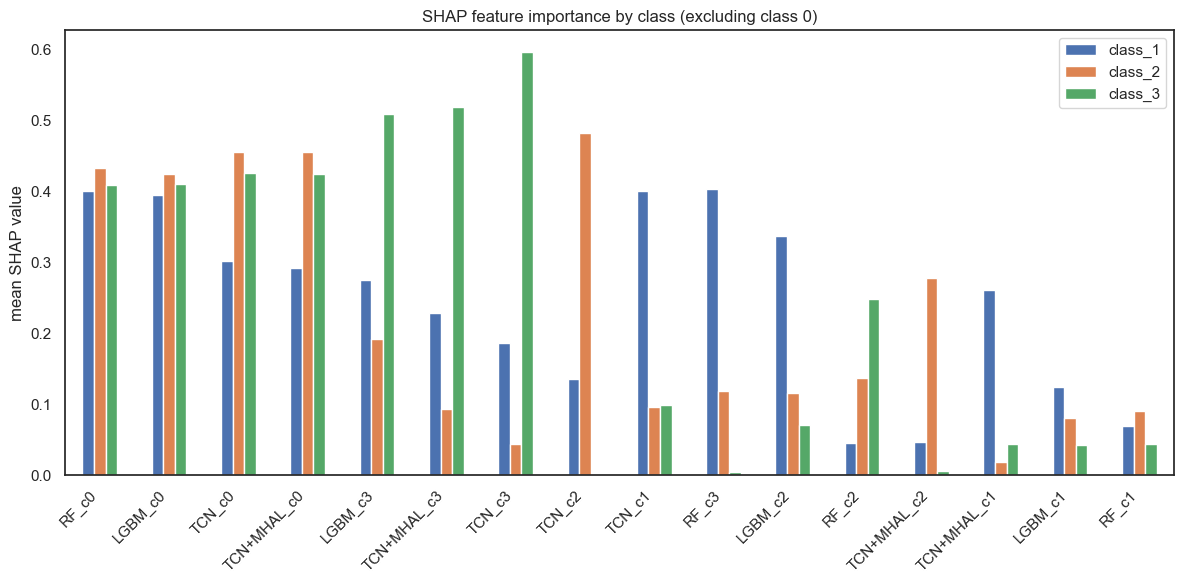

In [181]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sv = shap_values       # shape (n, f, c) = (500, 83, 4)
X = X_meta                       # shape (500, 83) with column names

ignore_class = 0           # set None if you want all classes
top_k = 20                    # how many features to show

# choose classes to plot
classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

# mean absolute shap per feature per class -> (f, len(classes))
imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

# dataframe for plotting
df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

# pick top features by average importance across plotted classes
top_features = df.mean(axis=1).sort_values(ascending=False).head(top_k).index
df_top = df.loc[top_features]

# plot grouped bars (different colors automatically)
ax = df_top.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("mean SHAP value")
ax.set_title("SHAP feature importance by class" + (f" (excluding class {ignore_class})" if ignore_class is not None else ""))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


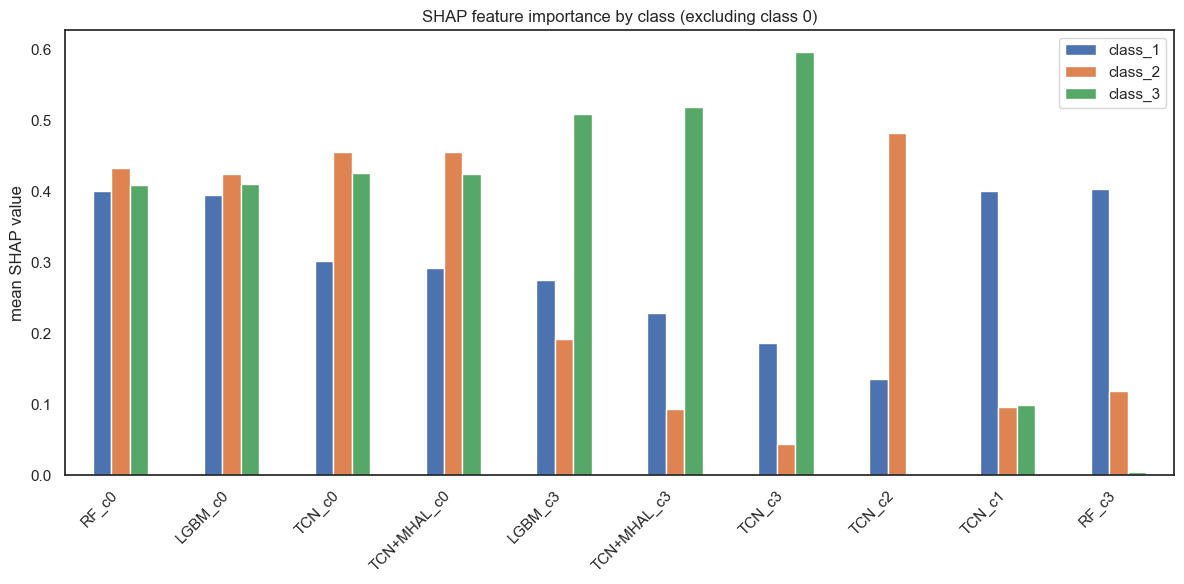

In [183]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sv = shap_values       # shape (n, f, c) = (500, 83, 4)
X = X_meta                       # shape (500, 83) with column names

ignore_class = 0           # set None if you want all classes
top_k = 10                    # how many features to show

# choose classes to plot
classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

# mean absolute shap per feature per class -> (f, len(classes))
imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

# dataframe for plotting
df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

# pick top features by average importance across plotted classes
top_features = df.mean(axis=1).sort_values(ascending=False).head(top_k).index
df_top = df.loc[top_features]

# plot grouped bars (different colors automatically)
ax = df_top.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("mean SHAP value")
ax.set_title("SHAP feature importance by class" + (f" (excluding class {ignore_class})" if ignore_class is not None else ""))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## test on AZT1D

In [ ]:
from joblib import dump, load

X_test_AZT1D, X_feat_test_AZT1D , Y_test_cat_AZT1D, Y_test_AZT1D = load("Data/AZT1D.joblib")

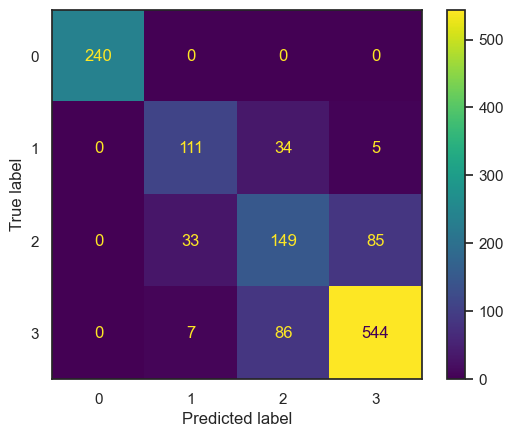


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7351    0.7400    0.7375       150
           2     0.5539    0.5581    0.5560       267
           3     0.8580    0.8540    0.8560       637

    accuracy                         0.8068      1294
   macro avg     0.7868    0.7880    0.7874      1294
weighted avg     0.8074    0.8068    0.8071      1294



In [144]:
y_pred_prob_rf_AZT1D = model_rf.predict_proba(X_feat_test_AZT1D)
y_pred_labels_rf_AZT1D = model_rf.predict(X_feat_test_AZT1D)

ConfusionMatrixDisplay.from_predictions(Y_test_AZT1D, y_pred_labels_rf_AZT1D)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_AZT1D, y_pred_labels_rf_AZT1D, digits=4))

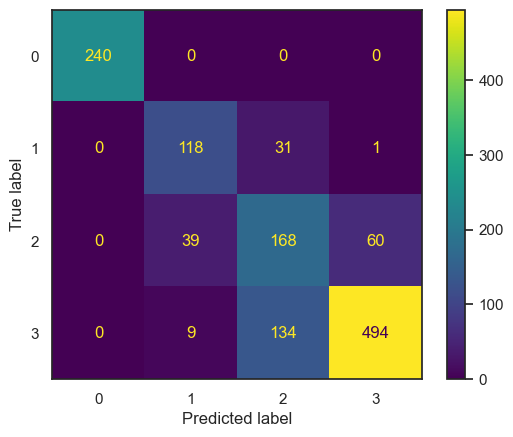


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7108    0.7867    0.7468       150
           2     0.5045    0.6292    0.5600       267
           3     0.8901    0.7755    0.8289       637

    accuracy                         0.7883      1294
   macro avg     0.7764    0.7978    0.7839      1294
weighted avg     0.8101    0.7883    0.7956      1294



In [147]:
#shap based feature analysis of LighGBM model 
X_test_feat_all_df_AZT1D = pd.DataFrame(X_feat_test_AZT1D, columns=a)

y_pred_labels_lbgm_AZT1D  = model_lbgm.predict(X_test_feat_all_df_AZT1D)
y_pred_prob_lbgm_AZT1D  = model_lbgm.predict_proba(X_test_feat_all_df_AZT1D)
ConfusionMatrixDisplay.from_predictions(Y_test_AZT1D, y_pred_labels_lbgm_AZT1D)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_AZT1D, y_pred_labels_lbgm_AZT1D, digits=4))

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


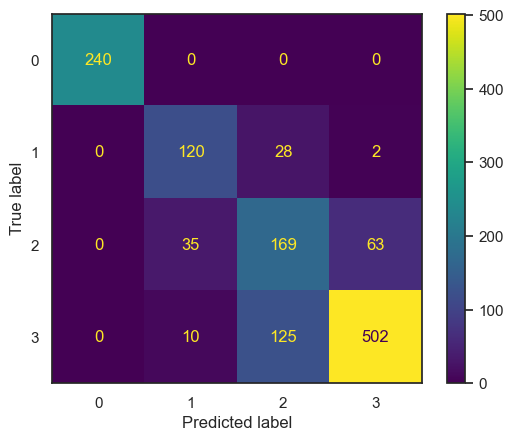

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7273    0.8000    0.7619       150
           2     0.5248    0.6330    0.5739       267
           3     0.8854    0.7881    0.8339       637

    accuracy                         0.7968      1294
   macro avg     0.7844    0.8053    0.7924      1294
weighted avg     0.8139    0.7968    0.8027      1294



In [148]:
sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix



predictions_tcn_AZT1D = model_tcn.predict(X_test_AZT1D)

y_pred_tcn_AZT1D = np.argmax(predictions_tcn_AZT1D, axis=1) 
    

final_preds_tcn_AZT1D = y_pred_tcn_AZT1D

y_true_labels_tcn_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_AZT1D, final_preds_tcn_AZT1D)
plt.show()

report_tcn_AZT1D = classification_report(y_true_labels_tcn_AZT1D, final_preds_tcn_AZT1D, digits=4)
print(report_tcn_AZT1D)

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


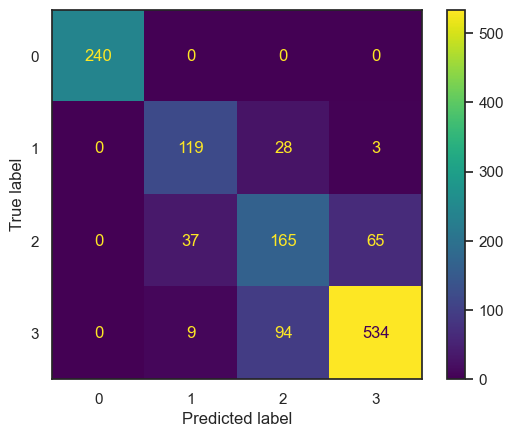

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7212    0.7933    0.7556       150
           2     0.5749    0.6180    0.5957       267
           3     0.8870    0.8383    0.8620       637

    accuracy                         0.8176      1294
   macro avg     0.7958    0.8124    0.8033      1294
weighted avg     0.8244    0.8176    0.8203      1294



In [149]:
predictions_tcn_mhal_AZT1D = model_tcn_mhal.predict(X_test_AZT1D)

y_pred_tcn_mhal_AZT1D = np.argmax(predictions_tcn_mhal_AZT1D, axis=1) 
    
final_preds_tcn_mhal_AZT1D = y_pred_tcn_mhal_AZT1D

y_true_labels_tcn_mhal_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal_AZT1D, final_preds_tcn_mhal_AZT1D)
plt.show()

report_fcn_tcn_mhal_AZT1D= classification_report(y_true_labels_tcn_mhal_AZT1D, final_preds_tcn_mhal_AZT1D, digits=4)
print(report_fcn_tcn_mhal_AZT1D)

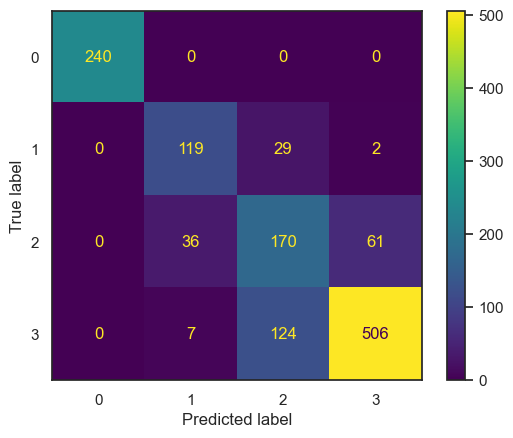

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7346    0.7933    0.7628       150
           2     0.5263    0.6367    0.5763       267
           3     0.8893    0.7943    0.8391       637

    accuracy                         0.7998      1294
   macro avg     0.7875    0.8061    0.7946      1294
weighted avg     0.8170    0.7998    0.8059      1294



In [152]:
X_meta_test_AZT1D = np.hstack([y_pred_prob_rf_AZT1D, y_pred_prob_lbgm_AZT1D,predictions_tcn_AZT1D, predictions_tcn_mhal_AZT1D]) # ,predictions_fcn, predictions_tcn, 
P_ens_test_AZT1D = meta.predict_proba(X_meta_test_AZT1D)
y_pred_AZT1D = P_ens_test_AZT1D.argmax(axis=1)

y_true_labels_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_AZT1D,y_pred_AZT1D)
plt.show()

report_fcn_AZT1D = classification_report(y_true_labels_AZT1D, y_pred_AZT1D, digits=4)
print(report_fcn_AZT1D)

In [153]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []



y_pred_prob= P_ens_test_AZT1D
y_pred_labels = y_pred_AZT1D

Y_test_all = Y_test_AZT1D
Y_test_rs = Y_test_cat_AZT1D

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("model_stack_AZT1D.txt", "w") as f:


    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[0.9999999999999999, 0.8365086910745138, 0.6115367639174354, 0.9319027240398515]]
Mac PR AUC: ([np.float64(0.8449870447579502)])


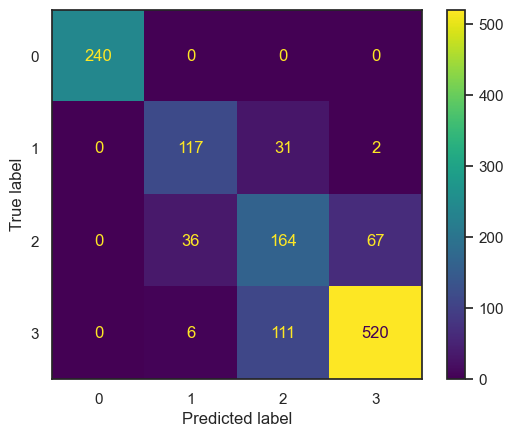

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7358    0.7800    0.7573       150
           2     0.5359    0.6142    0.5724       267
           3     0.8829    0.8163    0.8483       637

    accuracy                         0.8045      1294
   macro avg     0.7887    0.8026    0.7945      1294
weighted avg     0.8160    0.8045    0.8090      1294



In [154]:
all_proba = np.mean(
    np.stack([y_pred_prob_rf_AZT1D, y_pred_prob_lbgm_AZT1D,predictions_tcn_AZT1D, predictions_tcn_mhal_AZT1D], axis=0),
    axis=0
) #FCN_proba,

y_pred_all = np.argmax(all_proba, axis=1) 

y_true_labels = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_all)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred_all, digits=4)
print(report_fcn)

## T1 UDM

In [ ]:
X_test_T1DUOM, X_feat_test_T1DUOM, Y_test_cat_T1DUOM, Y_test_T1DUOM = load("Data/T1DUOM.joblib")

In [156]:
Y_test_T1DUOM.shape

(40971,)

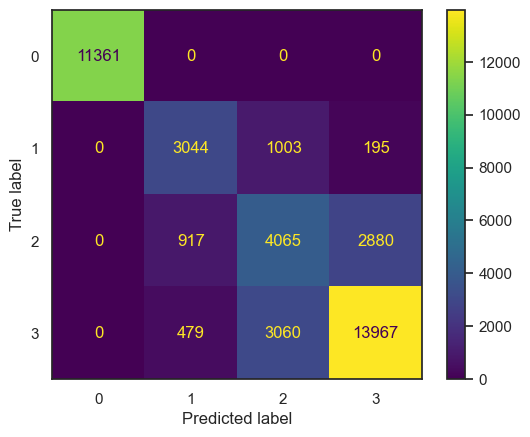


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     11361
           1     0.6856    0.7176    0.7012      4242
           2     0.5001    0.5170    0.5084      7862
           3     0.8196    0.7978    0.8086     17506

    accuracy                         0.7917     40971
   macro avg     0.7513    0.7581    0.7546     40971
weighted avg     0.7944    0.7917    0.7929     40971



In [157]:
y_pred_prob_rf_T1DUOM  = model_rf.predict_proba(X_feat_test_T1DUOM)
y_pred_labels_rf_T1DUOM = model_rf.predict(X_feat_test_T1DUOM)


ConfusionMatrixDisplay.from_predictions(Y_test_T1DUOM, y_pred_labels_rf_T1DUOM)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_T1DUOM, y_pred_labels_rf_T1DUOM , digits=4))

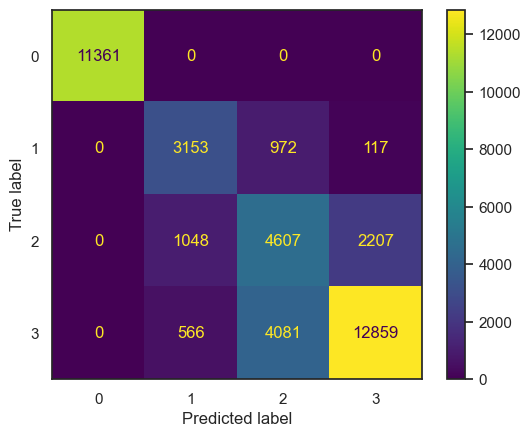


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     11361
           1     0.6614    0.7433    0.7000      4242
           2     0.4769    0.5860    0.5259      7862
           3     0.8469    0.7345    0.7867     17506

    accuracy                         0.7806     40971
   macro avg     0.7463    0.7660    0.7531     40971
weighted avg     0.7992    0.7806    0.7868     40971



In [158]:
#shap based feature analysis of LighGBM model 
X_test_feat_all_df_T1DUOM = pd.DataFrame(X_feat_test_T1DUOM , columns=a)

y_pred_labels_lbgm_T1DUOM  = model_lbgm.predict(X_test_feat_all_df_T1DUOM )
y_pred_prob_lbgm_T1DUOM   = model_lbgm.predict_proba(X_test_feat_all_df_T1DUOM )
ConfusionMatrixDisplay.from_predictions(Y_test_T1DUOM , y_pred_labels_lbgm_T1DUOM )
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_T1DUOM , y_pred_labels_lbgm_T1DUOM , digits=4))

1281/1281 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step


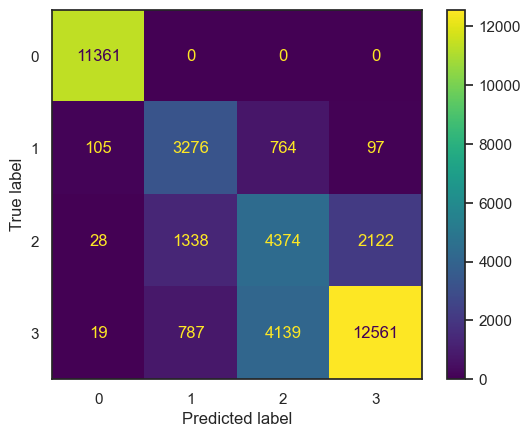

              precision    recall  f1-score   support

           0     0.9868    1.0000    0.9934     11361
           1     0.6066    0.7723    0.6795      4242
           2     0.4715    0.5563    0.5104      7862
           3     0.8499    0.7175    0.7781     17506

    accuracy                         0.7706     40971
   macro avg     0.7287    0.7615    0.7403     40971
weighted avg     0.7900    0.7706    0.7762     40971



In [159]:
sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix



predictions_tcn_T1DUOM  = model_tcn.predict(X_test_T1DUOM )

y_pred_tcn_T1DUOM  = np.argmax(predictions_tcn_T1DUOM , axis=1) 


final_preds_tcn_T1DUOM  = y_pred_tcn_T1DUOM 

y_true_labels_tcn_T1DUOM  = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_T1DUOM , final_preds_tcn_T1DUOM )
plt.show()

report_tcn_T1DUOM  = classification_report(y_true_labels_tcn_T1DUOM , final_preds_tcn_T1DUOM , digits=4)
print(report_tcn_T1DUOM )

1281/1281 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step


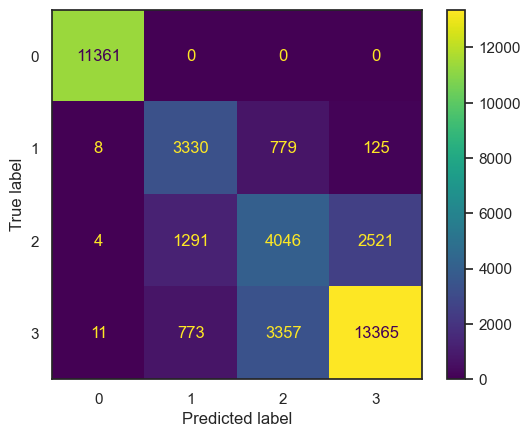

              precision    recall  f1-score   support

           0     0.9980    1.0000    0.9990     11361
           1     0.6174    0.7850    0.6912      4242
           2     0.4945    0.5146    0.5044      7862
           3     0.8347    0.7635    0.7975     17506

    accuracy                         0.7835     40971
   macro avg     0.7361    0.7658    0.7480     40971
weighted avg     0.7922    0.7835    0.7861     40971



In [160]:
predictions_tcn_mhal_T1DUOM = model_tcn_mhal.predict(X_test_T1DUOM )

y_pred_tcn_mhal_T1DUOM  = np.argmax(predictions_tcn_mhal_T1DUOM , axis=1) 
    
final_preds_tcn_mhal_T1DUOM = y_pred_tcn_mhal_T1DUOM 

y_true_labels_tcn_mhal_T1DUOM  = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal_T1DUOM , final_preds_tcn_mhal_T1DUOM )
plt.show()

report_fcn_tcn_mhal_T1DUOM = classification_report(y_true_labels_tcn_mhal_T1DUOM , final_preds_tcn_mhal_T1DUOM , digits=4)
print(report_fcn_tcn_mhal_T1DUOM )

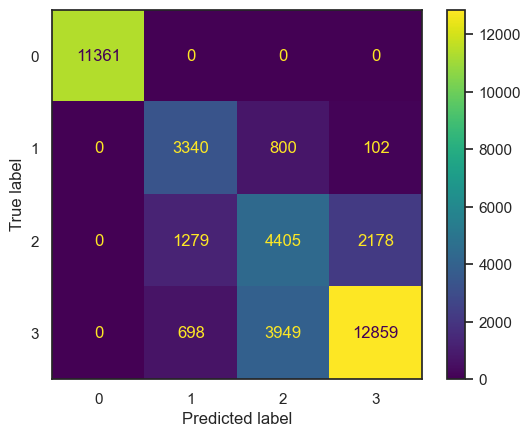

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     11361
           1     0.6282    0.7874    0.6988      4242
           2     0.4812    0.5603    0.5177      7862
           3     0.8494    0.7345    0.7878     17506

    accuracy                         0.7802     40971
   macro avg     0.7397    0.7706    0.7511     40971
weighted avg     0.7976    0.7802    0.7856     40971



In [161]:
X_meta_test_T1DUOM = np.hstack([y_pred_prob_rf_T1DUOM , y_pred_prob_lbgm_T1DUOM ,predictions_tcn_T1DUOM , predictions_tcn_mhal_T1DUOM ]) # ,predictions_fcn, predictions_tcn, 
P_ens_test_T1DUOM  = meta.predict_proba(X_meta_test_T1DUOM )
y_pred_T1DUOM  = P_ens_test_T1DUOM .argmax(axis=1)

y_true_labels_T1DUOM = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_T1DUOM ,y_pred_T1DUOM )
plt.show()

report_fcn_T1DUOM  = classification_report(y_true_labels_T1DUOM , y_pred_T1DUOM , digits=4)
print(report_fcn_T1DUOM)

In [162]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []



y_pred_prob= P_ens_test_T1DUOM
y_pred_labels = y_pred_T1DUOM

Y_test_all = Y_test_T1DUOM
Y_test_rs = Y_test_cat_T1DUOM

# === Step 7: Predict on Test Set ===
# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("model_stack_T1DUOM.txt", "w") as f:


    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")
   # f.write(f"STD Macro F1 Measure: {np.std(F1_macro):.4f}" +"\n\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")
   # f.write(f"STD Macro Recall: {np.std(Rec_macro):.4f}" +"\n\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")
   # f.write(f"STD Macro Precision: {np.std(Pre_macro):.4f}" +"\n\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")
  #  f.write(f"STD Macro PR AUC: {np.std(PR_AUC_Mac):.4f}" +"\n\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Class PR AUC: [[1.0, 0.7638822495591114, 0.492114859514274, 0.887967300330991]]
Mac PR AUC: ([np.float64(0.785991102351094)])


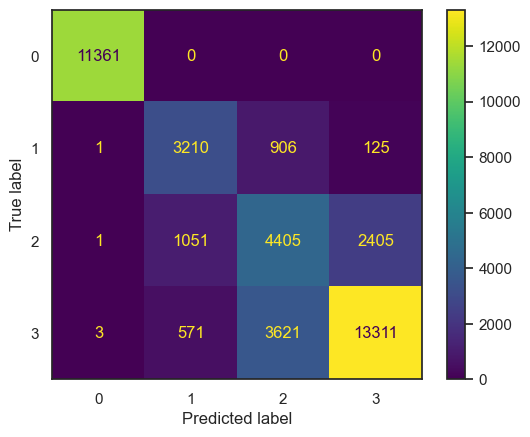

              precision    recall  f1-score   support

           0     0.9996    1.0000    0.9998     11361
           1     0.6643    0.7567    0.7075      4242
           2     0.4932    0.5603    0.5246      7862
           3     0.8403    0.7604    0.7983     17506

    accuracy                         0.7880     40971
   macro avg     0.7493    0.7693    0.7576     40971
weighted avg     0.7996    0.7880    0.7923     40971



In [163]:
all_proba = np.mean(
    np.stack([y_pred_prob_rf_T1DUOM , y_pred_prob_lbgm_T1DUOM ,predictions_tcn_T1DUOM , predictions_tcn_mhal_T1DUOM ], axis=0),
    axis=0
) #FCN_proba,

y_pred_all = np.argmax(all_proba, axis=1) 

y_true_labels = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_all)
plt.show()

report_fcn = classification_report(y_true_labels, y_pred_all, digits=4)
print(report_fcn)